# Теория вероятностей
## Домашнее задание

**Школа аналитиков hh.ru**

**Тема:** Теория вероятностей

---

# 2. Симуляции в Python



В этом разделе с помощью Python смоделируем три вероятностных распределения. Построим гистограммы, сравним результаты симуляций с теоретическими значениями и проверим центральную предельную теорему.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Фиксируем генератор случайных чисел
np.random.seed(42)



### 2.1. Нормальная выборка

Сгенерируем 5000 случайных значений нормального распределения со средним значением 40 и стандартным отклонением 8.

Построим гистограмму полученной выборки и сравним её с теоретической плотностью нормального распределения. Также сравним выборочное среднее и стандартное отклонение с заданными значениями.

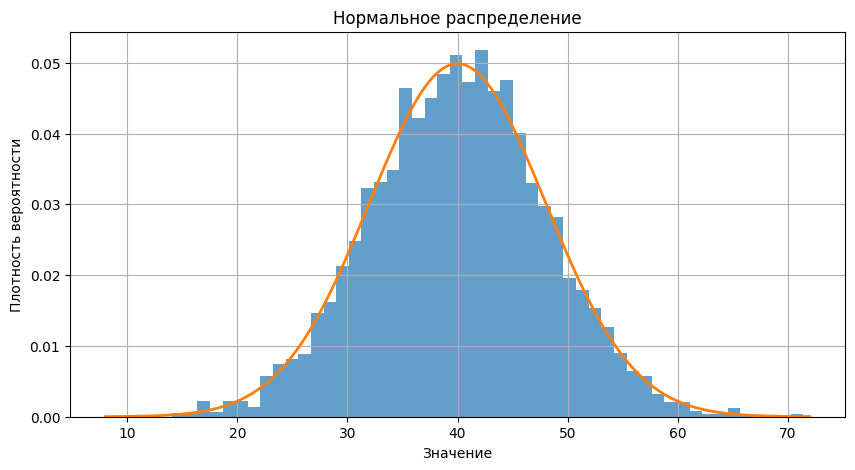

Теоретическое среднее: 40
Среднее выборки: 40.04
Теоретическое стандартное отклонение: 8
Стандартное отклонение выборки: 7.97


In [2]:
# Параметры распределения
mu = 40
sigma = 8
n = 5000

# Генерируем выборку
sample_normal = np.random.normal(mu, sigma, size=n)

# Считаем среднее и стандартное отклонение
sample_mean = sample_normal.mean()
sample_std = sample_normal.std(ddof=1)

# Строим гистограмму
plt.figure(figsize=(10, 5))
plt.hist(sample_normal, bins=50, density=True, alpha=0.7)

# Теоретическая плотность
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)
plt.plot(x, stats.norm.pdf(x, mu, sigma), linewidth=2)

plt.title('Нормальное распределение')
plt.xlabel('Значение')
plt.ylabel('Плотность вероятности')
plt.grid()
plt.show()

# Выводим результаты
print('Теоретическое среднее:', mu)
print('Среднее выборки:', round(sample_mean, 2))
print('Теоретическое стандартное отклонение:', sigma)
print('Стандартное отклонение выборки:', round(sample_std, 2))

**Вывод:**

Полученная гистограмма имеет форму, близкую к нормальному распределению. Выборочное среднее и стандартное отклонение близки к заданным значениям 40 и 8. Небольшие различия объясняются случайностью генерации выборки.

### 2.2. Биномиальная выборка

Сгенерируем 5000 значений биномиального распределения с параметрами n = 1000 и p = 0,04.

Каждое значение показывает количество успехов (откликов) среди 1000 независимых испытаний при вероятности успеха 4%.

Построим гистограмму и сравним её с теоретической функцией вероятности. Затем сравним выборочное среднее и стандартное отклонение с теоретическими значениями.

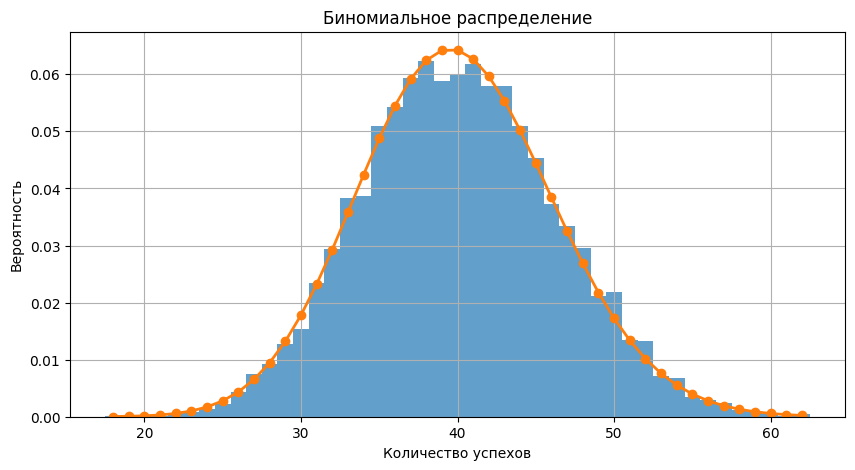

Теоретическое среднее: 40.0
Среднее выборки: 40.14
Теоретическое стандартное отклонение: 6.2
Стандартное отклонение выборки: 6.25


In [3]:
# Параметры биномиального распределения
n = 1000
p = 0.04
size = 5000

# Генерируем выборку
sample_binomial = np.random.binomial(n, p, size=size)

# Теоретические значения
theoretical_mean = n * p
theoretical_std = np.sqrt(n * p * (1 - p))

# Значения выборки
sample_mean = sample_binomial.mean()
sample_std = sample_binomial.std(ddof=1)

# Строим гистограмму
k = np.arange(sample_binomial.min(), sample_binomial.max() + 1)

plt.figure(figsize=(10, 5))
plt.hist(sample_binomial, bins=np.arange(
    sample_binomial.min() - 0.5,
    sample_binomial.max() + 1.5,
    1
), density=True, alpha=0.7)

# Теоретическая функция вероятности
plt.plot(k, stats.binom.pmf(k, n, p), 'o-', linewidth=2)

plt.title('Биномиальное распределение')
plt.xlabel('Количество успехов')
plt.ylabel('Вероятность')
plt.grid()
plt.show()

# Выводим результаты
print('Теоретическое среднее:', theoretical_mean)
print('Среднее выборки:', round(sample_mean, 2))
print('Теоретическое стандартное отклонение:', round(theoretical_std, 2))
print('Стандартное отклонение выборки:', round(sample_std, 2))

**Вывод:**

Гистограмма полученной выборки близка к теоретической функции вероятности биномиального распределения. Выборочное среднее близко к теоретическому значению 40, а стандартное отклонение — к значению примерно 6,20. Небольшие расхождения связаны со случайностью выборки.

### 2.3. Центральная предельная теорема

Сгенерируем выборку из 500 значений экспоненциального распределения и вычислим её среднее.

Повторим эту операцию 10 000 раз. Построим гистограмму полученных средних и посмотрим, какую форму принимает их распределение.

Цель — проверить центральную предельную теорему: при многократном усреднении случайных величин распределение средних становится приблизительно нормальным.

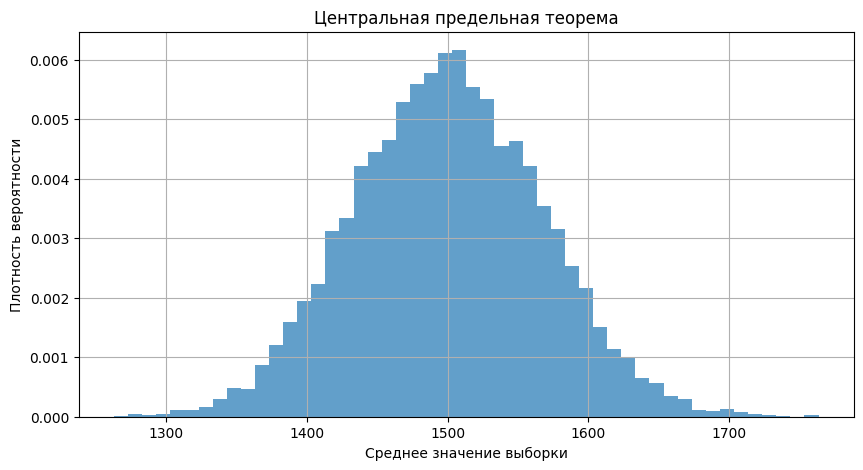

Теоретическое среднее: 1500
Среднее полученных средних: 1499.99
Теоретическое стандартное отклонение средних: 67.08
Стандартное отклонение полученных средних: 66.93


In [4]:
# Параметры симуляции
n_per_day = 500
n_days = 10000
scale = 1500

# Генерируем 10 000 выборок и считаем среднее каждой
daily_means = [
    np.random.exponential(scale=scale, size=n_per_day).mean()
    for _ in range(n_days)
]

# Строим гистограмму средних
plt.figure(figsize=(10, 5))
plt.hist(daily_means, bins=50, density=True, alpha=0.7)

plt.title('Центральная предельная теорема')
plt.xlabel('Среднее значение выборки')
plt.ylabel('Плотность вероятности')
plt.grid()
plt.show()

# Сравниваем полученные результаты с теорией
print('Теоретическое среднее:', scale)
print('Среднее полученных средних:', round(np.mean(daily_means), 2))
print('Теоретическое стандартное отклонение средних:',
      round(scale / np.sqrt(n_per_day), 2))
print('Стандартное отклонение полученных средних:',
      round(np.std(daily_means, ddof=1), 2))

**Вывод:**

Исходное экспоненциальное распределение имеет правостороннюю асимметрию. Однако гистограмма средних значений, полученных в результате 10 000 повторений, имеет форму, близкую к нормальному распределению.

Это подтверждает центральную предельную теорему: при усреднении большого количества независимых случайных величин распределение их средних становится приблизительно нормальным.

### 3.1. Расчёт стандартной ошибки

Для каждой группы рассчитаем стандартную ошибку конверсии по формуле:

\[
SE = \sqrt{\frac{p(1-p)}{n}}
\]

где p — конверсия, n — количество соискателей.

Затем сравним стандартные ошибки с разницей конверсий между группами.

In [5]:
# Данные старой кнопки
n1 = 5000
p1 = 0.031

# Данные новой кнопки
n2 = 5000
p2 = 0.034

# Рассчитываем стандартные ошибки
se1 = np.sqrt(p1 * (1 - p1) / n1)
se2 = np.sqrt(p2 * (1 - p2) / n2)

# Разница конверсий
difference = p2 - p1

# Стандартная ошибка разницы
se_difference = np.sqrt(se1**2 + se2**2)

print('Стандартная ошибка старой кнопки:',
      round(se1 * 100, 3), 'п.п.')

print('Стандартная ошибка новой кнопки:',
      round(se2 * 100, 3), 'п.п.')

print('Разница конверсий:',
      round(difference * 100, 3), 'п.п.')

print('Стандартная ошибка разницы:',
      round(se_difference * 100, 3), 'п.п.')

Стандартная ошибка старой кнопки: 0.245 п.п.
Стандартная ошибка новой кнопки: 0.256 п.п.
Разница конверсий: 0.3 п.п.
Стандартная ошибка разницы: 0.355 п.п.


**Вывод:**

Стандартная ошибка старой кнопки составляет примерно 0,245 процентного пункта, новой — 0,256 процентного пункта.

Разница конверсий составляет 0,3 процентного пункта, а стандартная ошибка разницы — примерно 0,355 процентного пункта.

Разница меньше стандартной ошибки. Поэтому пока нельзя уверенно утверждать, что новая кнопка действительно улучшила конверсию. Возможно, наблюдаемый рост объясняется случайными колебаниями.

### 3.2. Проверка с помощью симуляции

Предположим, что новая кнопка не оказывает влияния на конверсию. В таком случае вероятность отклика в обеих группах одинакова.

Используем общую конверсию двух групп — 3,25%.

Многократно смоделируем две группы по 5000 соискателей. Для каждой симуляции рассчитаем разницу конверсий и определим, как часто случайная разница по модулю достигает 0,3 процентного пункта или больше.

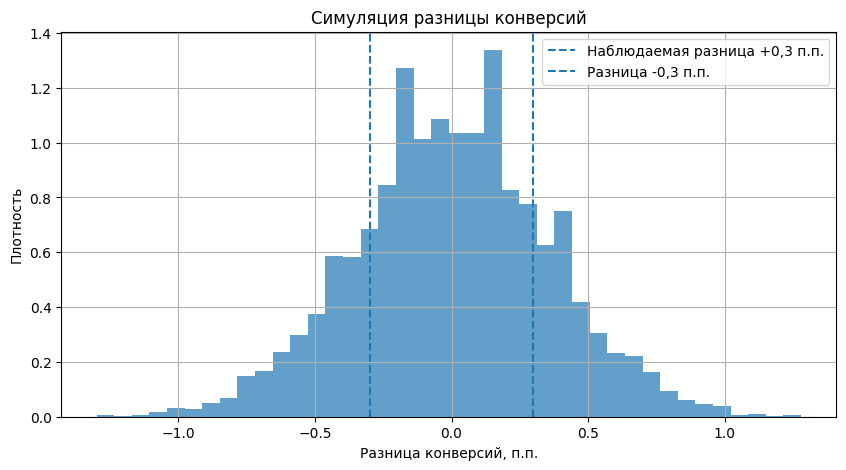

Общая конверсия: 3.25 %
Наблюдаемая разница: 0.3 п.п.
Доля симуляций с такой разницей или больше: 38.93 %


In [6]:
# Общая конверсия двух групп
p_common = (155 + 170) / (5000 + 5000)

# Количество симуляций
n_simulations = 10000

# Моделируем количество откликов в двух группах
group1 = np.random.binomial(5000, p_common, size=n_simulations)
group2 = np.random.binomial(5000, p_common, size=n_simulations)

# Рассчитываем разницу конверсий
differences = group2 / 5000 - group1 / 5000

# Наблюдаемая разница
observed_difference = 0.034 - 0.031

# Считаем, как часто разница достигает 0,3 п.п. или больше
probability = np.mean(np.abs(differences) >= observed_difference)

# Строим гистограмму
plt.figure(figsize=(10, 5))
plt.hist(differences * 100, bins=40, density=True, alpha=0.7)

plt.axvline(0.3, linestyle='--', label='Наблюдаемая разница +0,3 п.п.')
plt.axvline(-0.3, linestyle='--', label='Разница -0,3 п.п.')

plt.title('Симуляция разницы конверсий')
plt.xlabel('Разница конверсий, п.п.')
plt.ylabel('Плотность')
plt.legend()
plt.grid()
plt.show()

print('Общая конверсия:', round(p_common * 100, 2), '%')
print('Наблюдаемая разница:', round(observed_difference * 100, 2), 'п.п.')
print('Доля симуляций с такой разницей или больше:',
      round(probability * 100, 2), '%')

**Вывод:**

При условии, что новая кнопка не влияет на конверсию, в симуляциях иногда возникает разница, равная наблюдаемым 0,3 процентного пункта или превышающая её.

Это означает, что такую разницу можно получить случайно. Поэтому имеющихся данных недостаточно, чтобы уверенно утверждать, что новая кнопка улучшила конверсию.

### 3.3. Выбросы во времени сессий

Даны значения времени сессий пользователей в минутах:

3, 4, 4, 5, 5, 6, 6, 7, 8, 52.

Найдём выбросы двумя способами:

1. Правило трёх сигм.
2. Метод перцентилей (правило Тьюки).

Сравним результаты и определим, какой метод лучше подходит для этих данных.

In [7]:
# Исходные данные
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

# Среднее и стандартное отклонение
mean = x.mean()
std = x.std(ddof=1)

# Правило трёх сигм
lower_3s = mean - 3 * std
upper_3s = mean + 3 * std

outliers_3s = x[(x < lower_3s) | (x > upper_3s)]

# Метод перцентилей
q1, q3 = np.percentile(x, [25, 75])
iqr = q3 - q1

lower_tukey = q1 - 1.5 * iqr
upper_tukey = q3 + 1.5 * iqr

outliers_tukey = x[(x < lower_tukey) | (x > upper_tukey)]

# Вывод результатов
print('Среднее:', round(mean, 2))
print('Стандартное отклонение:', round(std, 2))

print('\nПравило трёх сигм:')
print('Нижняя граница:', round(lower_3s, 2))
print('Верхняя граница:', round(upper_3s, 2))
print('Выбросы:', outliers_3s)

print('\nМетод перцентилей:')
print('Q1:', q1)
print('Q3:', q3)
print('IQR:', iqr)
print('Нижняя граница:', lower_tukey)
print('Верхняя граница:', upper_tukey)
print('Выбросы:', outliers_tukey)

Среднее: 10.0
Стандартное отклонение: 14.83

Правило трёх сигм:
Нижняя граница: -34.5
Верхняя граница: 54.5
Выбросы: []

Метод перцентилей:
Q1: 4.25
Q3: 6.75
IQR: 2.5
Нижняя граница: 0.5
Верхняя граница: 10.5
Выбросы: [52]


**Вывод:**

Правило трёх сигм не обнаружило выбросов, так как значение 52 не превышает верхнюю границу.

Метод перцентилей обнаружил значение 52 как выброс, поскольку оно значительно превышает верхнюю границу 10,5.

В данном случае метод перцентилей сработал лучше, так как значение 52 сильно увеличивает среднее и стандартное отклонение, из-за чего правило трёх сигм не обнаруживает его.